# Usagi Visual Identifier: Project Journey

This notebook tells the complete project story from collecting my own doll photographs through the final known test and the decision to build a private personal catalog. Detailed notebooks remain available for each individual experiment.

© 2026 Emma Tong. All rights reserved.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
plt.style.use("seaborn-v0_8-whitegrid")
print("Project root resolved without storing a machine specific path")

Project root resolved without storing a machine specific path


## 1. Why I built this

My master's schedule does not leave room for a formal computer vision course, so I wanted a small project where I could collect real data, adapt a pretrained model, run controlled experiments, and understand the failures. My Usagi dolls made the problem personal. Many variants share the same face and body, while a hat, bow, costume, or prop carries the identity.

## 2. How the system evolved

```mermaid
flowchart LR
    A[Owner photos] --> B[Prepared JPEGs]
    B --> C[Frozen DINOv2]
    C --> D[Nearest image retrieval]
    C --> E[Linear probe]
    C --> F[Partial fine tuning]
    D --> G[Confidence check]
    F --> G
    G --> H[Personal catalog]
```

The experiments became more complex only after a simpler baseline was measured.

## 3. Dataset design

The split is based on capture sessions rather than random neighboring photographs. This tests whether the system works under a different setup rather than memorizing nearly identical frames.

In [2]:
sessions = pd.DataFrame(
    [
        ("Session 1", "Training gallery", 98, "Known"),
        ("Session 2", "Validation", 42, "Known"),
        ("Session 3", "Final test", 42, "Known"),
        ("Session 4", "Validation", 51, "Unknown"),
    ],
    columns=["Session", "Role", "Photographs", "Identity status"],
)
sessions

,Session,Role,Photographs,Identity status
0,Session 1,Training gallery,98,Known
1,Session 2,Validation,42,Known
2,Session 3,Final test,42,Known
3,Session 4,Validation,51,Unknown


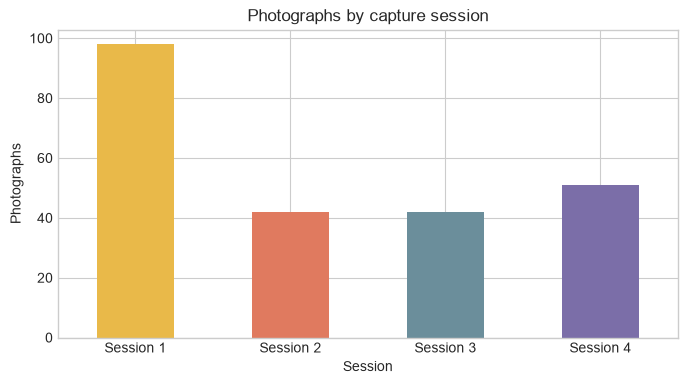

In [3]:
ax = sessions.set_index("Session")["Photographs"].plot.bar(
    figsize=(8, 4), color=["#e9b949", "#e07a5f", "#6b8e9b", "#7b6ea8"]
)
ax.set_ylabel("Photographs")
ax.set_title("Photographs by capture session")
plt.xticks(rotation=0)
plt.show()

## 4. The seven catalog identities

These are personal identities rather than claims about an official complete merchandise catalog. Informal names are enough to keep the labels stable while I learn more about each doll.

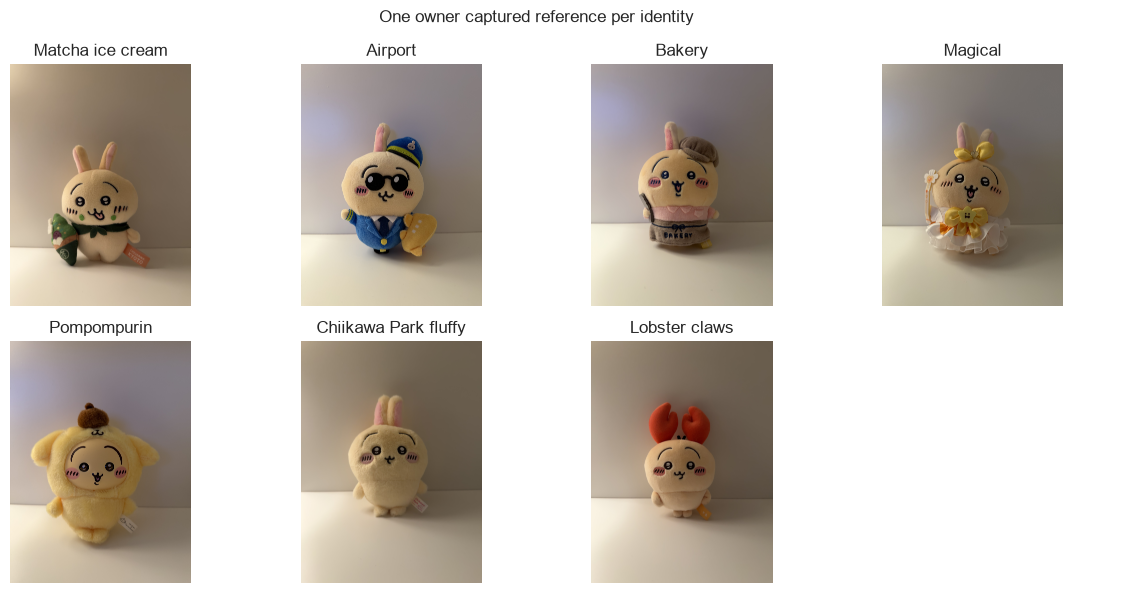

In [4]:
catalog = pd.read_csv(PROJECT_ROOT / "data/private/catalog.csv")
manifest = pd.read_csv(PROJECT_ROOT / "data/private/images.csv")
prepared = pd.read_csv(PROJECT_ROOT / "data/processed/images.csv")
joined = manifest.merge(
    prepared[["image_id", "processed_relative_path"]], on="image_id"
)
joined = joined.merge(
    catalog[["catalog_id", "display_name"]], left_on="catalog_id", right_on="catalog_id"
)
samples = (
    joined[joined["split"] == "train"]
    .groupby("catalog_id", sort=True)
    .first()
    .reset_index()
)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (_, row) in zip(axes.flat, samples.iterrows(), strict=False):
    with Image.open(
        PROJECT_ROOT / "data/processed" / row["processed_relative_path"]
    ) as image:
        ax.imshow(image.convert("RGB"))
    ax.set_title(row["display_name"])
    ax.axis("off")
for ax in axes.flat[len(samples) :]:
    ax.axis("off")
fig.suptitle("One owner captured reference per identity")
plt.tight_layout()
plt.show()

## 5. Frozen embedding baseline

DINOv2 Small turns each image into a 384 number CLS embedding. L2 normalization makes cosine similarity equal to a dot product. Nearest image retrieval compares a query with the 98 Session 1 reference vectors and keeps direct evidence about which photograph supported the result.

## 6. Aggregation comparison

Nearest image, identity prototypes, a top k mean, and weighted neighbors all identified all 42 Session 2 validation photos correctly. Nearest image remained preferred because extra aggregation complexity produced no validation gain.

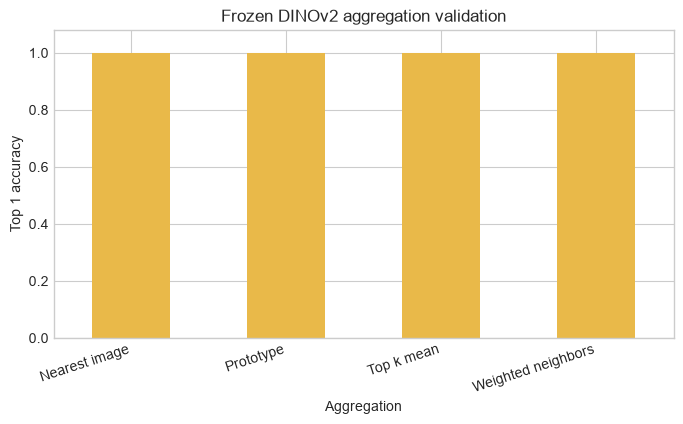

In [5]:
aggregation = pd.DataFrame(
    [
        ("Nearest image", 1.0),
        ("Prototype", 1.0),
        ("Top k mean", 1.0),
        ("Weighted neighbors", 1.0),
    ],
    columns=["Aggregation", "Session 2 Top 1"],
)
ax = aggregation.set_index("Aggregation")["Session 2 Top 1"].plot.bar(
    figsize=(8, 4), color="#e9b949"
)
ax.set_ylim(0, 1.08)
ax.set_ylabel("Top 1 accuracy")
ax.set_title("Frozen DINOv2 aggregation validation")
plt.xticks(rotation=18, ha="right")
plt.show()

## 7. Linear probe

The linear probe freezes DINOv2 and trains one affine layer from 384 embedding values to seven logits. It also reached perfect Session 2 accuracy. It proved that the frozen features were already linearly separable, but it did not outperform the simpler retrieval workflow or make new identities easy to add.

## 8. Partial fine tuning

```mermaid
flowchart LR
    A[Image] --> B[DINOv2 blocks 1 through 11 frozen]
    B --> C[Block 12 trained]
    C --> D[Final normalization trained]
    D --> E[384 value CLS embedding]
    E --> F[Seven class head trained]
```

Only the final transformer block, final normalization, and classifier head were updated. Conservative augmentation changed crops, rotation, brightness, contrast, saturation, and hue within small identity preserving limits.

In [6]:
training = pd.DataFrame(
    [
        ("Conservative augmentation", 42, 0.00341),
        ("No augmentation", 42, 0.00607),
    ],
    columns=["Policy", "Correct validation photos", "Mean validation loss"],
)
training

,Policy,Correct validation photos,Mean validation loss
0,Conservative augmentation,42,0.00341
1,No augmentation,42,0.00607


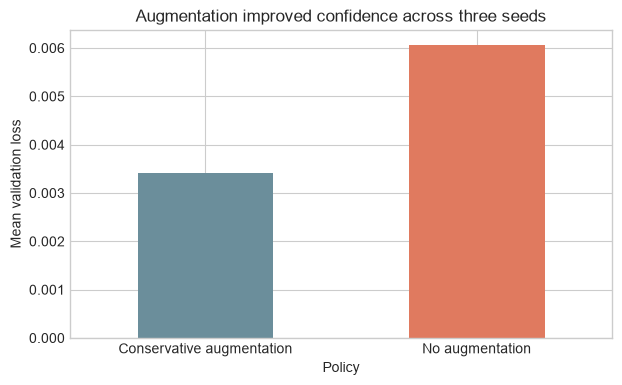

In [7]:
ax = training.set_index("Policy")["Mean validation loss"].plot.bar(
    figsize=(7, 4), color=["#6b8e9b", "#e07a5f"]
)
ax.set_ylabel("Mean validation loss")
ax.set_title("Augmentation improved confidence across three seeds")
plt.xticks(rotation=0)
plt.show()

## 9. What the ablations established

The project compared frozen features, a trained head, a trained final block plus head, conservative augmentation, no augmentation, and three seeds. This is enough to decide that deeper unfreezing is not justified. Partial fine tuning improved validation loss but did not improve final Top 1 accuracy.

## 10. Unknown rejection validation

Session 4 contained a crocheted banana, crocheted rabbit, Usagi posture pal, and sloth plush. The important difficult case was posture pal because it shares the Usagi face, ears, color, and body shape with known dolls.

In [8]:
unknown_results = pd.DataFrame(
    [
        ("Frozen maximum similarity", 40, 7),
        ("Tuned maximum similarity", 41, 4),
        ("Tuned prototype similarity", 40, 0),
        ("Tuned classifier margin", 40, 0),
    ],
    columns=["System", "Correct known accepted", "Unknown accepted"],
)
unknown_results

,System,Correct known accepted,Unknown accepted
0,Frozen maximum similarity,40,7
1,Tuned maximum similarity,41,4
2,Tuned prototype similarity,40,0
3,Tuned classifier margin,40,0


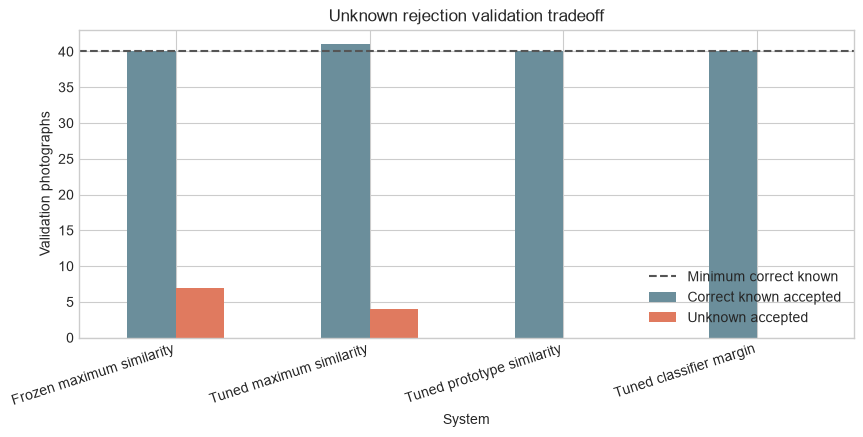

In [9]:
ax = unknown_results.set_index("System")[
    ["Correct known accepted", "Unknown accepted"]
].plot.bar(figsize=(10, 4), color=["#6b8e9b", "#e07a5f"])
ax.axhline(40, color="#555555", linestyle="--", label="Minimum correct known")
ax.set_ylabel("Validation photographs")
ax.set_title("Unknown rejection validation tradeoff")
plt.xticks(rotation=18, ha="right")
plt.legend()
plt.show()

## 11. Limits of the unknown result

The zero false accept results are validation findings, not proof of general unknown rejection. I decided not to collect or redistribute third party social media images. There is no independent unknown final test, so the application must describe uncertainty honestly.

## 12. One time final known test

Session 3 was opened only after the checkpoint, aggregation rules, and thresholds were frozen. No model or threshold can be changed in response to these results.

In [10]:
final_test = pd.DataFrame(
    [
        ("Frozen nearest", 41, 42, 33),
        ("Tuned nearest", 41, 42, 35),
        ("Tuned prototype", 40, 42, 34),
        ("Tuned classifier", 40, 42, 38),
    ],
    columns=["System", "Top 1 correct", "Top 3 correct", "Correct accepted"],
)
final_test

,System,Top 1 correct,Top 3 correct,Correct accepted
0,Frozen nearest,41,42,33
1,Tuned nearest,41,42,35
2,Tuned prototype,40,42,34
3,Tuned classifier,40,42,38


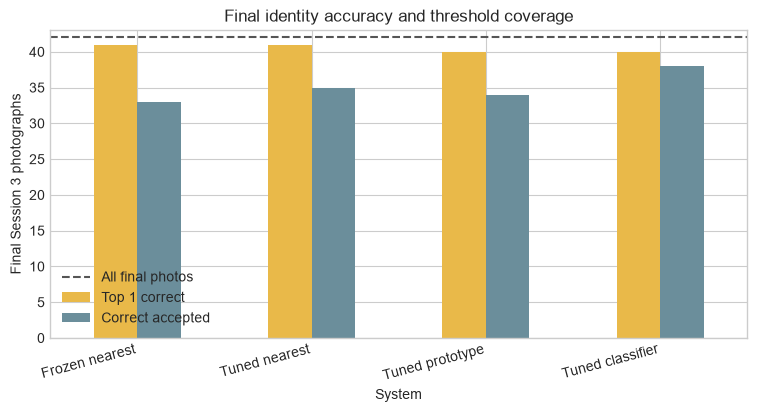

In [11]:
ax = final_test.set_index("System")[["Top 1 correct", "Correct accepted"]].plot.bar(
    figsize=(9, 4), color=["#e9b949", "#6b8e9b"]
)
ax.axhline(42, color="#555555", linestyle="--", label="All final photos")
ax.set_ylabel("Final Session 3 photographs")
ax.set_title("Final identity accuracy and threshold coverage")
plt.xticks(rotation=15, ha="right")
plt.legend()
plt.show()

## 13. Final failure pattern

Frozen and tuned nearest retrieval both confused one Pompompurin view with Chiikawa Park fluffy. Prototype retrieval and the classifier made that error and also confused one Airport view with Matcha ice cream. Every correct identity still appeared in the top three. Raw ranking generalized better than the validation selected confidence thresholds.

## 14. Main modeling conclusion

Nearest image retrieval remains the preferred identification system. It tied the best final Top 1 result, keeps reference evidence, requires no trained classifier head, and can accept a new personal identity by adding reference images. Metric learning remains optional because the current data cannot test whether it generalizes to truly new merchandise identities.

## 15. New product direction

```mermaid
flowchart TD
    A[Upload one doll photo] --> B[Local nearest image retrieval]
    B --> C{Confidence state}
    C -->|Confident| D[Open personal catalog record]
    C -->|Possible| E[Show top three and reference evidence]
    C -->|No confident local match| F[Optional web assisted lookup]
    F --> G[Candidate names and source links]
    G --> H[Manual confirmation]
    H --> I[Create or update personal catalog record]
```

## 16. Personal catalog scope

The catalog will track dolls I own, dolls I know exist, dolls I want, and dolls I do not want. A record can hold an informal preferred name, distinguishing details, verification status, owner captured references, reviewed source links, and timestamped availability notes. It does not need to represent every Usagi product.

## 17. Discovery and copyright boundary

Web lookup is an explicit private discovery action, not a source of automatic training data. The application should use an official API, return candidate source pages, avoid scraping, avoid committing downloaded images, and require my confirmation before saving information. Credentials, query history, and personal collection details stay outside Git.

## 18. What comes next

The active roadmap now focuses on calibrated uncertainty, a local web interface, a small SQLite personal catalog, manual verification, provenance, and an optional web assisted lookup. Metric learning, multi doll detection, and independent unknown testing are future work rather than blockers.

## 19. Detailed notebooks

The embedding baseline, aggregation comparison, linear probe, partial fine tuning, unknown rejection, and open set model selection notebooks contain the complete educational walkthroughs behind this summary.

In [12]:
print("Preferred identification system: frozen DINOv2 nearest image retrieval")
print("Final known Top 1: 41 of 42")
print("Final known Top 3: 42 of 42")
print("Independent unknown final test: not available")
print("Next milestone: private personal catalog application")

Preferred identification system: frozen DINOv2 nearest image retrieval
Final known Top 1: 41 of 42
Final known Top 3: 42 of 42
Independent unknown final test: not available
Next milestone: private personal catalog application
